# Step 1 : Introduction to CNNs


Convolutional Neural Network, neural network designed for analyzing visual data. This model learn to 'see' the world by identifying patterns.
It recognize patterns with a grid-like structure.

The model process images by passing them through multiple layers, each of them identifying a feature (edges, lines, ...). The deeper layers recognize more complex patterns (shapes, whole objects, ...).

The layers :
- Convolutional layer : identifying simple feature (straight edge, curve, color, ...)
- Activation layer : reviewing of the map created by the cconvolutional layer, it keeps the strong signals and get rid of the weak ones. It ensures that only the important features are kept, preventing noise from cluttering the process
- Pooling layer : summarize the findings from small patches of the feature map, reducing the size of the data
- Fully connected layer : looks at the high-level combination features (whiskers, ...), draws a conclusion (cat or dog)

# Step 2: Dataset Exploration

In [156]:
# imports
import os
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix

base_dir = "cats_and_dogs_filtered/"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

### How many cat and dog images are there in the training and validation directories?

In [157]:
# Image count
def count_images(directory):
    counts = {}
    for cls in sorted(os.listdir(directory)):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_dir)
val_counts = count_images(val_dir)

print("Train : ", train_counts)
print("Validation : ", val_counts)

Train :  {'cats': 1000, 'dogs': 1000}
Validation :  {'cats': 500, 'dogs': 500}


##### There are :

|      | training set | validation set |
|------|--------------|----------------|
| cats | 1000 cats    | 500 cats       |
| dogs | 1000 dogs    | 500 dogs       |


##### This means a class distribution of 50% each.

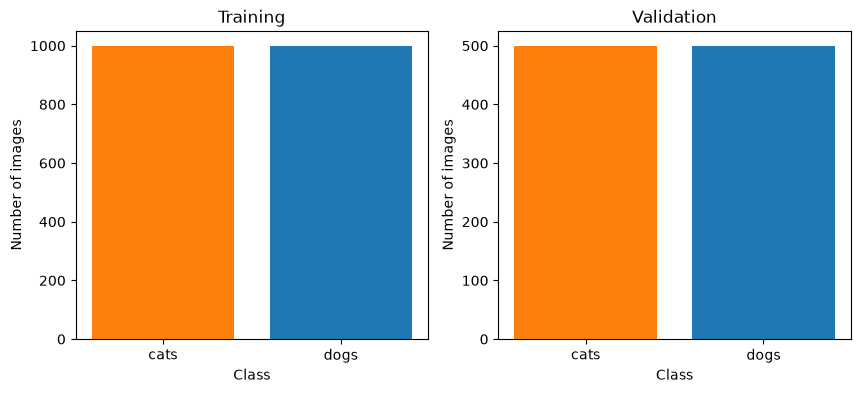

In [158]:
#Vizualization :
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, counts, title in zip(
    axes,
    [train_counts, val_counts],
    ["Training", "Validation"]
):
    ax.bar(
        counts.keys(),
        counts.values(),
        color=["tab:orange", "tab:blue"]
    )

    ax.set_title(title)
    ax.set_ylabel("Number of images")
    ax.set_xlabel("Class")

plt.show()

## Create the dataset :

In [159]:
# Image parameters
IMG_SIZE = (150, 150)
BATCH_SIZE = 100
SEED = 42


In [160]:
def create_datasets(IMG_SIZE : tuple[int,int], BATCH_SIZE=100 , SEED=10 , validationsplit=0.2) -> tuple[tf.data.Dataset]:
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=validationsplit,
        subset="training", 
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    test_dataset = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=validationsplit,
        subset="validation", 
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_dataset = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    return train_dataset, test_dataset, val_dataset

In [161]:
train_dataset, test_dataset, validation_dataset = create_datasets(IMG_SIZE, BATCH_SIZE, SEED)

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.
Found 1000 files belonging to 2 classes.


In [162]:
print(f"There are : {len(train_dataset)*BATCH_SIZE} images inside the train_dataset")
print(f"There are : {len(test_dataset)*BATCH_SIZE} images inside the test_dataset")
print(f"There are : {len(validation_dataset)*BATCH_SIZE} images inside the validation_dataset")

There are : 1600 images inside the train_dataset
There are : 400 images inside the test_dataset
There are : 1000 images inside the validation_dataset


### Vizualize images from the dataset :

In [163]:
def display_image(dataset, classes):
    plt.figure(figsize=(10, 10))
    i=0
    for images, labels in dataset.take(2):
        ax = plt.subplot(1, 2, i + 1)
        plt.imshow(images[0].numpy().astype("uint8"))
        plt.title(classes[labels[0]])
        plt.axis("off")
        i+=1

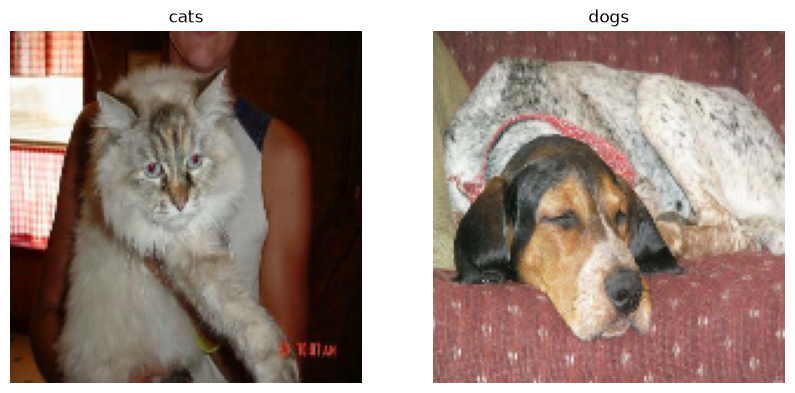

In [164]:
display_image(train_dataset,train_dataset.class_names)

# Step 3: Build Your CNN Model

In [165]:

def create_model(IMG_SIZE : tuple[int,int], padding = None, Conv2D_start_filters=32, Conv2D_kernel_size=(3,3), 
                 Conv2D_strides=(1,1),Conv2D_dilation_rate = (1,1), Conv_padding = "same",  
                 Pooling_Pool_size=(2,2), Pooling_strides=None, Pool_padding= "valid",
                 Dense_units=128, 
                 Dropout_rate=0, Dropout_Seed=24,
                 Data_augmentation=False,
                 Print=True) -> tf.keras.Sequential :
    """
    - Padding : Value is "same" or "valid" represents if we use pixels outside the image (set to 0)
    There are two specific values for the Convolution and the pooling which can be set separately.
    But if this global value is set it will overwrite that choice.

    - Conv2D_Start filter is the number of filter for the first layer of Convolution.
    It will then double at each layer.
    - Conv2D_kernel_size represents the size of pixel taken each time the convolution is calculated.
    - Conv2D_strides represents the number of skipped pixel each time the convolution moves.
    - Conv2D_dilation_rate represents the number of pixels in between two kernel pixels.

    - Pooling_Pool_size represents by how much we reduce the IMG size 
    - Pooling_Strides represents the number of skipped pixel each time the pooling moves.
    Can be left 'None' and will be calculated from the pool_size.

    - Dense_units represents the number of units we use in the Dense layer.

    - Dropout_rate is a percentage, it represents the number of forgotten images each time.
    - Dropout_Seed represents a seed to always forget the same images.

    - Data_augmentation is a boolean value to set to True if you want to use data_augmentation.

    - Print, Do we print the summary or not?
    """
    IMG_size_with_pixel_colors = (IMG_SIZE[0], IMG_SIZE[1], 3)

    if (padding != None):
        Conv_padding = padding
        Pool_padding = padding

    model = tf.keras.Sequential([

        tf.keras.layers.InputLayer(shape=IMG_size_with_pixel_colors, name="Input"),

        tf.keras.layers.Rescaling(1./255, name="Scaling"), 

        tf.keras.layers.RandomFlip("horizontal",name="Data_Augmentation_horizontal_flip") if Data_augmentation else tf.keras.layers.Identity(name="Data_augmentation_is_False_1"),
        tf.keras.layers.RandomFlip("vertical",name="Data_Augmentation_vertical_flip") if Data_augmentation else tf.keras.layers.Identity(name="Data_augmentation_is_False_2"),
        tf.keras.layers.RandomZoom(0.2, name="Data_Augmentation_Random_Zoom") if Data_augmentation else tf.keras.layers.Identity(name="Data_augmentation_is_False_3"),

        tf.keras.layers.Conv2D(Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer1_Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer1_MaxPooling"),

        tf.keras.layers.Conv2D(2*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer2_Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer2_MaxPooling"),

        tf.keras.layers.Conv2D(4*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer3_Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer3_MaxPooling"),

        tf.keras.layers.Conv2D(8*Conv2D_start_filters, Conv2D_kernel_size , Conv2D_strides , Conv_padding , dilation_rate=Conv2D_dilation_rate , activation="relu", name="Layer4_Convolution"),
        tf.keras.layers.MaxPool2D(Pooling_Pool_size, Pooling_strides , Pool_padding, name="Layer4_MaxPooling"),

        tf.keras.layers.Flatten(name="Flatten_images_to_use_the_Dense_layer"),

        tf.keras.layers.Dense(Dense_units, activation="relu", name="Dense_layer"),

        tf.keras.layers.Dropout(Dropout_rate, seed=Dropout_Seed, name=f"{"Unused_" if Dropout_rate==0 else ""}Dropout_layer"),  

        tf.keras.layers.Dense(1, activation="sigmoid", name="Last_deliberation_layer.")
    ])

    if (Print) :
        model.summary()

    return model

In [166]:
model = create_model(IMG_SIZE)

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Scaling (Rescaling)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_1    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_2    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_3    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_Convolution (Conv2D)     │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_MaxPooling               │ (None, 75, 75, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_Convolution (Conv2D)     │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_MaxPooling               │ (None, 37, 37, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_Convolution (Conv2D)     │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_MaxPooling               │ (None, 18, 18, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_Convolution (Conv2D)     │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_MaxPooling               │ (None, 9, 9, 256)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_images_to_use_the_Dens… │ (None, 20736)          │             0 │
│ (Flatten)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_layer (Dense)             │ (None, 128)            │     2,654,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Unused_Dropout_layer (Dropout)  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Last_deliberation_layer.        │ (None, 1)              │           129 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,042,881 (11.61 MB)

 Trainable params: 3,042,881 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

**Compilation:** Adam (standard optimizer, adaptive learning rate, converges fast) and binary cross-entropy (binary classification with one sigmoid output).

**Number of parameters:** Conv2D = F × (K×K×C_in + 1), Dense = (n_in + 1) × n_out
- Conv: 32×(3×3×3+1) + 64×(3×3×32+1) + 128×(3×3×64+1) + 256×(3×3×128+1) = 896 + 18,496 + 73,856 + 295,168 = 388,416
- Dense: (20736+1)×128 + 128×1 = 2,654,336
- **Total = 1,994,305**, same as `model.summary()`

In [167]:
def Compile_model(model : tf.keras.Sequential, optimizer_learning_rate: int | None = None,
                  optimizer = "adam", loss = "binary_crossentropy", metrics=["accuracy", "precision", "recall"]):
    if optimizer_learning_rate != None:
        optimizer = tf.keras.optimizers.Adam(learning_rate=optimizer_learning_rate)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=metrics
    )

    return model

# Step 4: Train the Model

In [168]:
def fit_model(model : tf.keras.Sequential, epochs=11, details=False) -> tf.keras.callbacks.History:
    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=epochs,
        verbose=details
    )
    return history

In [169]:
history = fit_model(model := Compile_model(create_model(IMG_SIZE,Print=False)),details=True)

Epoch 1/11


c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


16/16 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.5119 - loss: 0.7063 - precision: 0.5006 - recall: 0.5614 - val_accuracy: 0.5000 - val_loss: 0.6894 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 2/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.5206 - loss: 0.6903 - precision: 0.5097 - recall: 0.5038 - val_accuracy: 0.5150 - val_loss: 0.6838 - val_precision: 0.5078 - val_recall: 0.9760
Epoch 3/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.5863 - loss: 0.6715 - precision: 0.5719 - recall: 0.6100 - val_accuracy: 0.6130 - val_loss: 0.6659 - val_precision: 0.7148 - val_recall: 0.3760
Epoch 4/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.6350 - loss: 0.6512 - precision: 0.6562 - recall: 0.5320 - val_accuracy: 0.6560 - val_loss: 0.6374 - val_precision: 0.7179 - val_recall: 0.5140
Epoch 5/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.6544 - loss: 0.6261 - precision: 0.6440 - recall: 0.6547 - val_accuracy: 0.6560 - val_loss: 0.6257 - val_precision:

In [170]:
def plot_history(history, title):
    metrics = ["loss", "accuracy", "precision", "recall"]
    plt.figure(figsize=(12, 8))
    for i in range(metrics.__len__()):
        plt.subplot(2, 2, i+1)
        plt.plot(history.history[f"{metrics[i]}"], label="train")
        plt.plot(history.history[f"val_{metrics[i]}"], label="validation")
        plt.title(title + f" - {metrics[i]}")
        plt.legend()

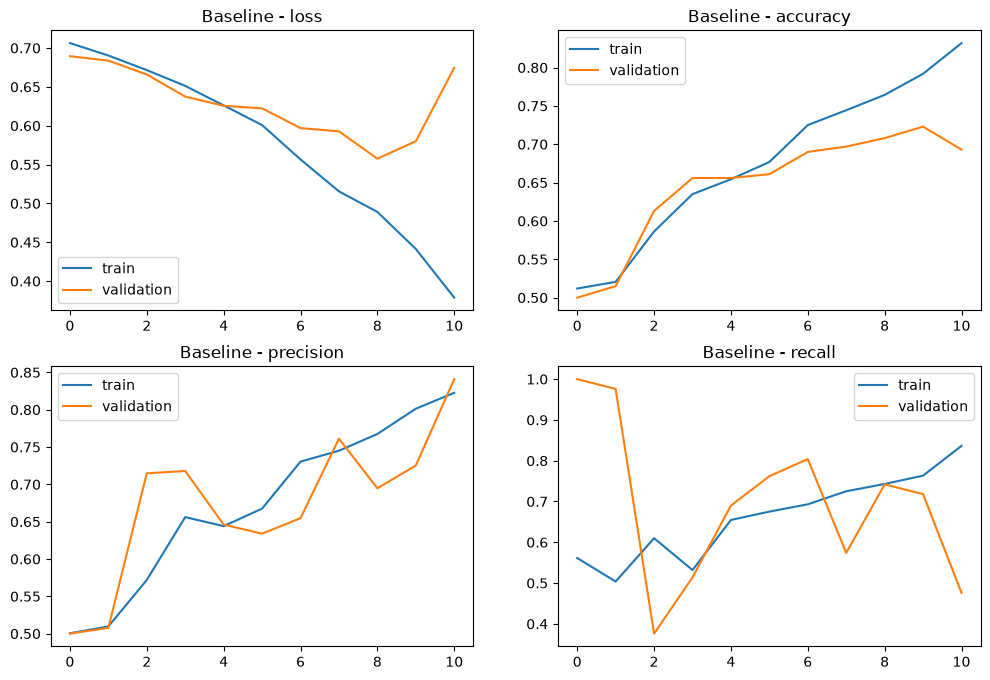

In [171]:
plot_history(history, "Baseline")

# Step 5: Evaluate the Model on the test set

### Basic Evaluation

In [172]:
values = model.evaluate(test_dataset)
metrics = ["Loss", "Accuracy", "Precision", "Recall"]
for i in range(values.__len__()):
    print(f"Test {metrics[i]}: {values[i]:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - accuracy: 0.7075 - loss: 0.6736 - precision: 0.9106 - recall: 0.5138
Test Loss: 0.6736
Test Accuracy: 0.7075
Test Precision: 0.9106
Test Recall: 0.5138


## Full evaluation :
Adds all the labels to a single ndarray, same for the predictions.

In [173]:
# Preparation of the values :
label = np.array([])
predictions = np.array([[]])
for images, labels in test_dataset:

    label = np.append(label,labels.numpy(),axis=0)

    predictions = np.append(predictions, model.predict(images, verbose=0))

predictions = np.around(predictions)

In [174]:
print(test_dataset.class_names)

['cats', 'dogs']


value 0 means 'cats'

value 1 means 'dogs'

### Confusion matrix :

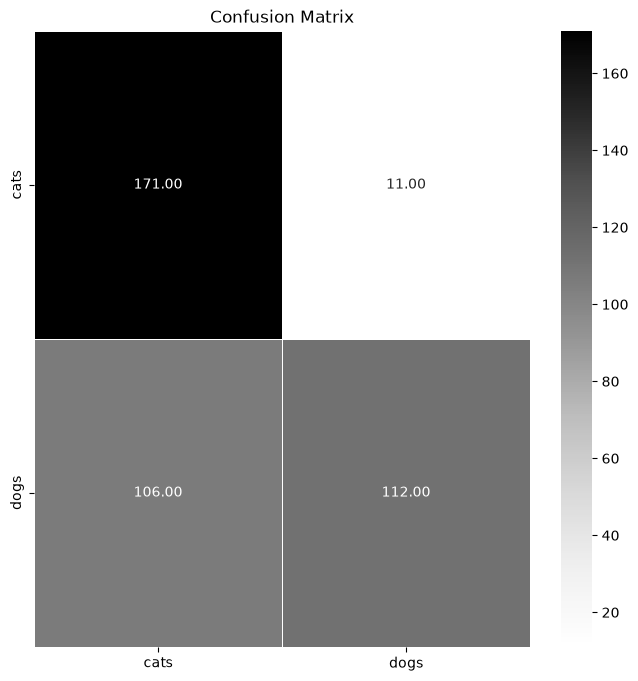

In [175]:
confusionmatrix = confusion_matrix(label, predictions)
plt.figure(figsize=(8,8))
sns.heatmap(confusionmatrix, annot=True, cmap="Greys", fmt=".2f", linewidths=0.5, xticklabels=test_dataset.class_names, yticklabels=test_dataset.class_names)

plt.title("Confusion Matrix")
plt.show()

### Accuracy

In [176]:
accuracy_score(label, predictions)

0.7075

### Precision

In [177]:
precision_score(label, predictions)

0.9105691056910569

### Recall

In [178]:
recall_score(label, predictions)

0.5137614678899083

### F1-score

In [179]:
f1_score(label, predictions)

0.656891495601173

## Function pipeline to be reused in part 6:

In [180]:
def Full_evaluation_display(values : tuple, label=None, predictions=None):

    if (not label is None) and (not predictions is None) :
        confusionmatrix = confusion_matrix(label, predictions)
        plt.figure(figsize=(8,8))
        sns.heatmap(confusionmatrix, annot=True, cmap="Greys", fmt=".2f", linewidths=0.5, xticklabels=test_dataset.class_names, yticklabels=test_dataset.class_names)

        plt.title("Confusion Matrix")
        plt.show()

    metrics = ["Loss", "Accuracy", "Precision", "Recall", "F1-score"]
    for i in range(values.__len__()):
        print(f"Test {metrics[i]}: {values[i]:.4f}")

In [181]:
def Full_evaluation(model : tf.keras.Sequential, Print: bool = False):
    values = model.evaluate(test_dataset, verbose=0)

    label = np.array([])
    predictions = np.array([[]])
    for images, labels in test_dataset:

        label = np.append(label,labels.numpy(),axis=0)

        predictions = np.append(predictions, model.predict(images, verbose=0))

    predictions = np.around(predictions)

    values.append(f1_score(label, predictions))

    if Print :
        Full_evaluation_display(values, label, predictions)

    return values

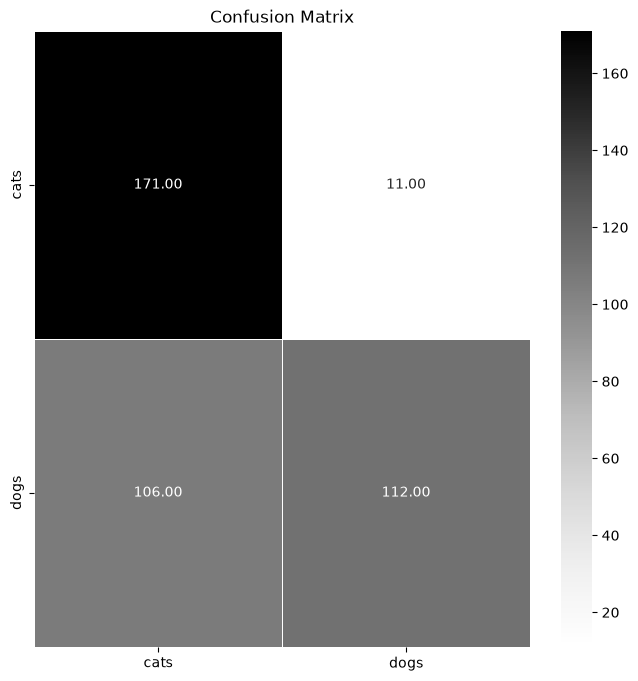

Test Loss: 0.6736
Test Accuracy: 0.7075
Test Precision: 0.9106
Test Recall: 0.5138
Test F1-score: 0.6569


In [182]:
vals = Full_evaluation(model, Print=True)

# Step 6: Try to Improve the Model

## Data Augmentation

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Scaling (Rescaling)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_Augmentation_horizontal_f… │ (None, 150, 150, 3)    │             0 │
│ (RandomFlip)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_Augmentation_vertical_flip │ (None, 150, 150, 3)    │             0 │
│ (RandomFlip)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_Augmentation_Random_Zoom   │ (None, 150, 150, 3)    │             0 │
│ (RandomZoom)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_Convolution (Conv2D)     │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_MaxPooling               │ (None, 75, 75, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_Convolution (Conv2D)     │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_MaxPooling               │ (None, 37, 37, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_Convolution (Conv2D)     │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_MaxPooling               │ (None, 18, 18, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_Convolution (Conv2D)     │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_MaxPooling               │ (None, 9, 9, 256)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_images_to_use_the_Dens… │ (None, 20736)          │             0 │
│ (Flatten)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_layer (Dense)             │ (None, 128)            │     2,654,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Unused_Dropout_layer (Dropout)  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Last_deliberation_layer.        │ (None, 1)              │           129 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,042,881 (11.61 MB)

 Trainable params: 3,042,881 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


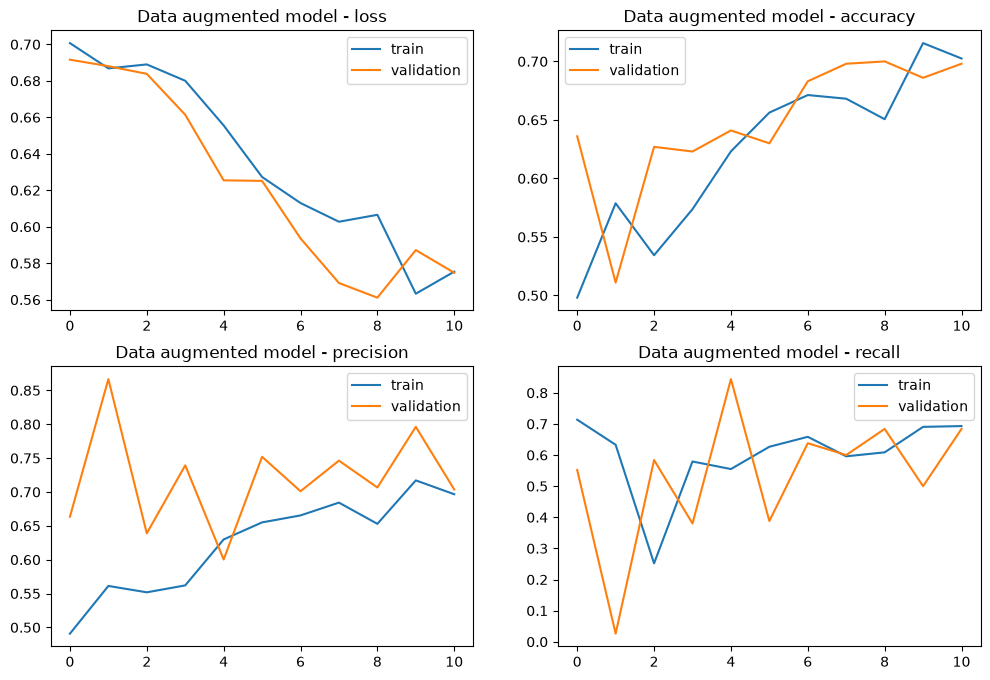

In [183]:
history = fit_model(model_aug := Compile_model(create_model(IMG_SIZE, Data_augmentation=True, Print=True)))
plot_history(history, "Data augmented model")

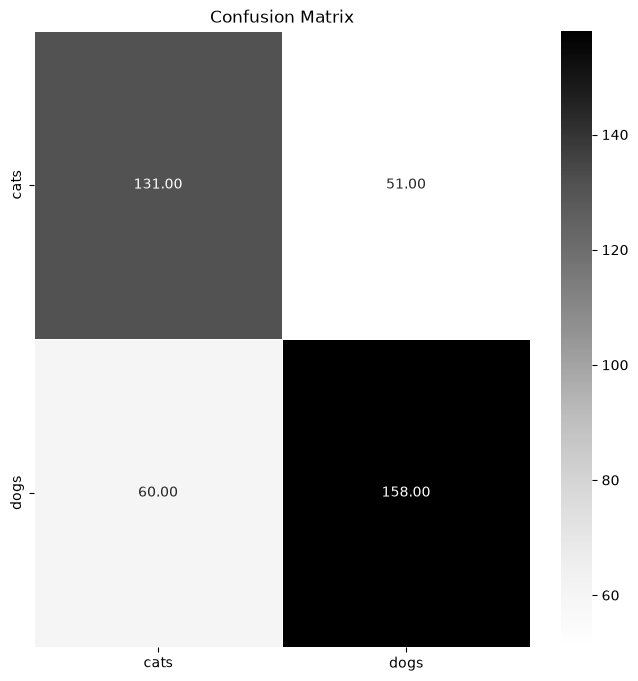

Test Loss: 0.5068
Test Accuracy: 0.7225
Test Precision: 0.7560
Test Recall: 0.7248
Test F1-score: 0.7400


[0.5068492293357849,
 0.7225000262260437,
 0.7559808492660522,
 0.7247706651687622,
 0.7400468384074942]

In [184]:
Full_evaluation(model_aug, Print=True)

## Dropout layers

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Scaling (Rescaling)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_1    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_2    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_augmentation_is_False_3    │ (None, 150, 150, 3)    │             0 │
│ (Identity)                      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_Convolution (Conv2D)     │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_MaxPooling               │ (None, 75, 75, 32)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_Convolution (Conv2D)     │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_MaxPooling               │ (None, 37, 37, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_Convolution (Conv2D)     │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_MaxPooling               │ (None, 18, 18, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_Convolution (Conv2D)     │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer4_MaxPooling               │ (None, 9, 9, 256)      │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten_images_to_use_the_Dens… │ (None, 20736)          │             0 │
│ (Flatten)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_layer (Dense)             │ (None, 128)            │     2,654,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Last_deliberation_layer.        │ (None, 1)              │           129 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,042,881 (11.61 MB)

 Trainable params: 3,042,881 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


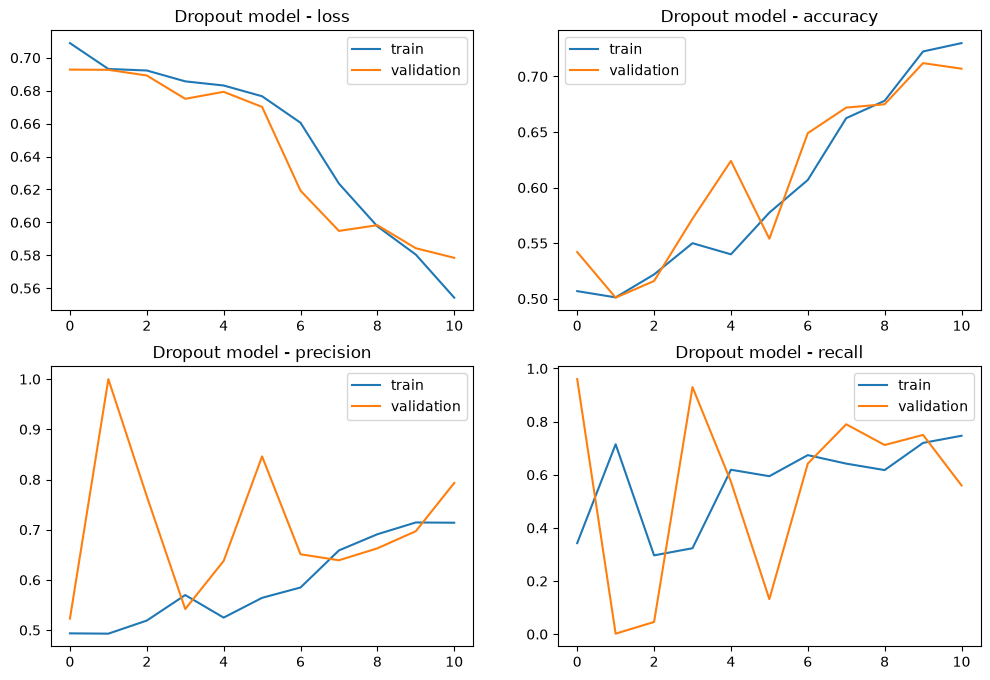

In [185]:
history = fit_model(model_drop := Compile_model(create_model(IMG_SIZE, Dropout_rate=0.5, Print=True)))
plot_history(history, "Dropout model")

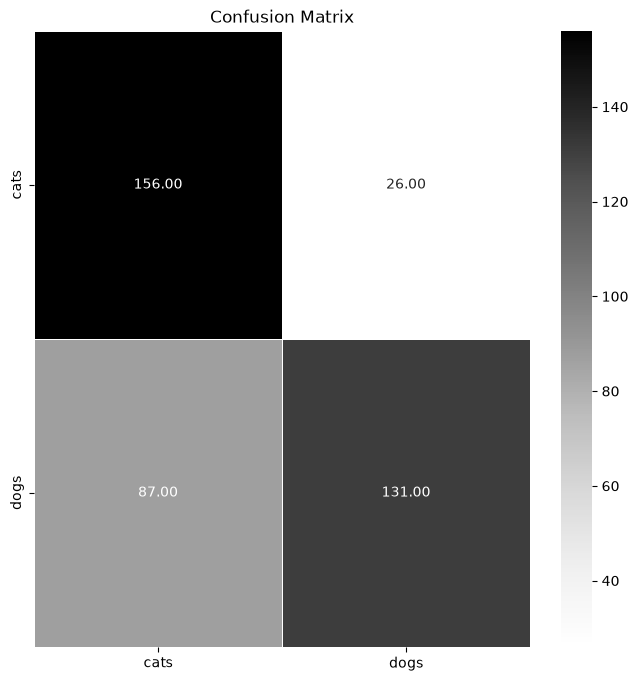

Test Loss: 0.5689
Test Accuracy: 0.7175
Test Precision: 0.8344
Test Recall: 0.6009
Test F1-score: 0.6987


[0.5689190626144409,
 0.7174999713897705,
 0.8343949317932129,
 0.6009174585342407,
 0.6986666666666667]

In [186]:
Full_evaluation(model_drop, Print=True)

## Batch normalization

This feature is already present by default inside `tf.data.dataset` since it uses a Batch size to load the dataset.

Which is afterwards used when fitting the CNN.

# Bonus Challenge: Transfer Learning

In [187]:
IMG_SIZE_TL = (224, 224)

train_dataset, test_dataset, validation_dataset = create_datasets(IMG_SIZE_TL, BATCH_SIZE, SEED)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE_TL[0], IMG_SIZE_TL[1], 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model_tl = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224, 224, 3), name="Scalling_MobileNetV2"),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(name="Global_Average_Pooling"),

    tf.keras.layers.Dense(1, activation="sigmoid", name="Last_deliberation_layer")
])

model_tl.summary()

Found 2000 files belonging to 2 classes.
Using 1600 files for training.
Found 2000 files belonging to 2 classes.
Using 400 files for validation.
Found 1000 files belonging to 2 classes.


c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Scalling_MobileNetV2            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Global_Average_Pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Last_deliberation_layer (Dense) │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [188]:
model_tl = Compile_model(model_tl, optimizer_learning_rate=0.001,
                         metrics=["accuracy", "precision", "recall"])

history_tl = fit_model(model_tl, details=True)

Epoch 1/11


c:\Users\laure\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


16/16 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.7663 - loss: 0.4836 - precision: 0.7757 - recall: 0.7340 - val_accuracy: 0.9590 - val_loss: 0.2428 - val_precision: 0.9655 - val_recall: 0.9520
Epoch 2/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9631 - loss: 0.1779 - precision: 0.9536 - recall: 0.9719 - val_accuracy: 0.9830 - val_loss: 0.1180 - val_precision: 0.9840 - val_recall: 0.9820
Epoch 3/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.9731 - loss: 0.1082 - precision: 0.9719 - recall: 0.9731 - val_accuracy: 0.9850 - val_loss: 0.0842 - val_precision: 0.9860 - val_recall: 0.9840
Epoch 4/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.9794 - loss: 0.0846 - precision: 0.9687 - recall: 0.9898 - val_accuracy: 0.9860 - val_loss: 0.0693 - val_precision: 0.9860 - val_recall: 0.9860
Epoch 5/11
16/16 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.9831 - loss: 0.0712 - precision: 0.9772 - recall: 0.9885 - val_accuracy: 0.9850 - val_loss: 0.0614 - val_precision:

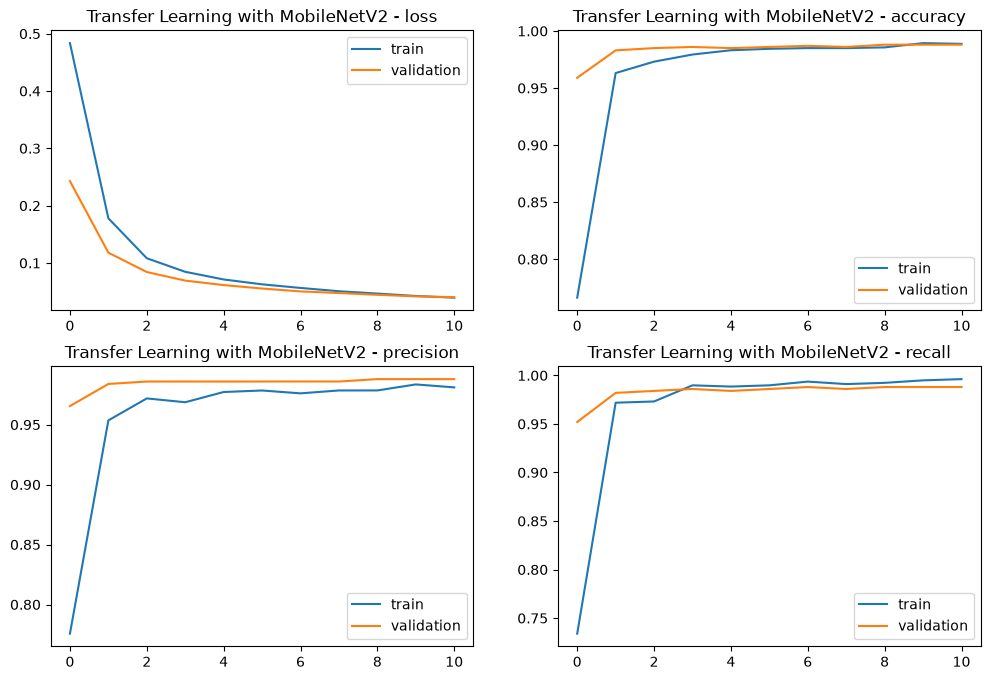

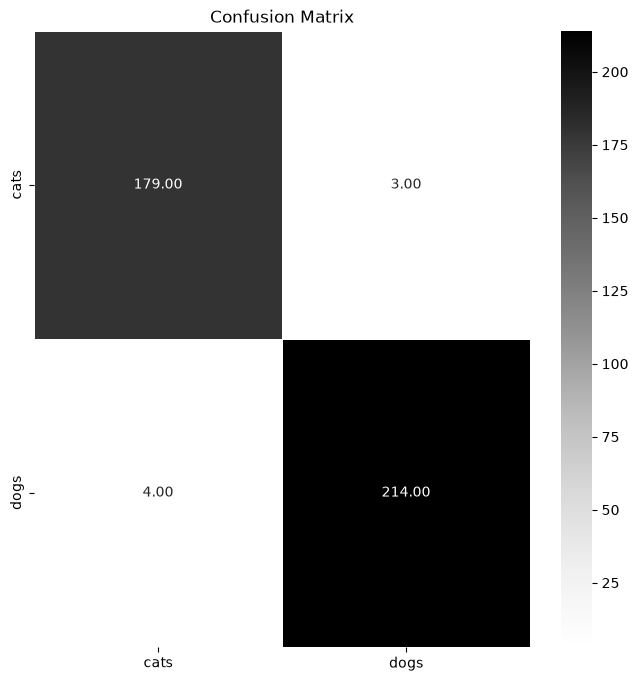

Test Loss: 0.0582
Test Accuracy: 0.9825
Test Precision: 0.9862
Test Recall: 0.9817
Test F1-score: 0.9839


In [189]:
plot_history(history_tl, "Transfer Learning with MobileNetV2") 

val_tl = Full_evaluation(model_tl, Print=True)